<a href="https://colab.research.google.com/github/fitraadhim/244107020089_MachineLearning/blob/main/JS05/tugasJS05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Instalasi pustaka hdbscan (jika belum terinstal)
!pip install hdbscan

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Memuat dataset iris dari sklearn
iris = load_iris()
X = iris.data
y_true = iris.target  # Label asli untuk analisis perbandingan

# Melakukan standarisasi pada data fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape data fitur:", X_scaled.shape)
print("Label kelas asli:", np.unique(y_true))

Shape data fitur: (150, 4)
Label kelas asli: [0 1 2]


In [3]:
# Menginisialisasi dan melatih model HDBSCAN
# min_cluster_size disesuaikan agar cocok dengan ukuran dataset Iris yang kecil (150 sampel)
hdb = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=5)
hdb.fit(X_scaled)

labels = hdb.labels_
probabilities = hdb.probabilities_

# Menghitung jumlah cluster yang terbentuk (mengabaikan noise -1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
# Menghitung banyaknya noise
n_noise = list(labels).count(-1)

print(f"Jumlah cluster yang terbentuk: {n_clusters}")
print(f"Banyaknya noise points: {n_noise}")

Jumlah cluster yang terbentuk: 2
Banyaknya noise points: 2


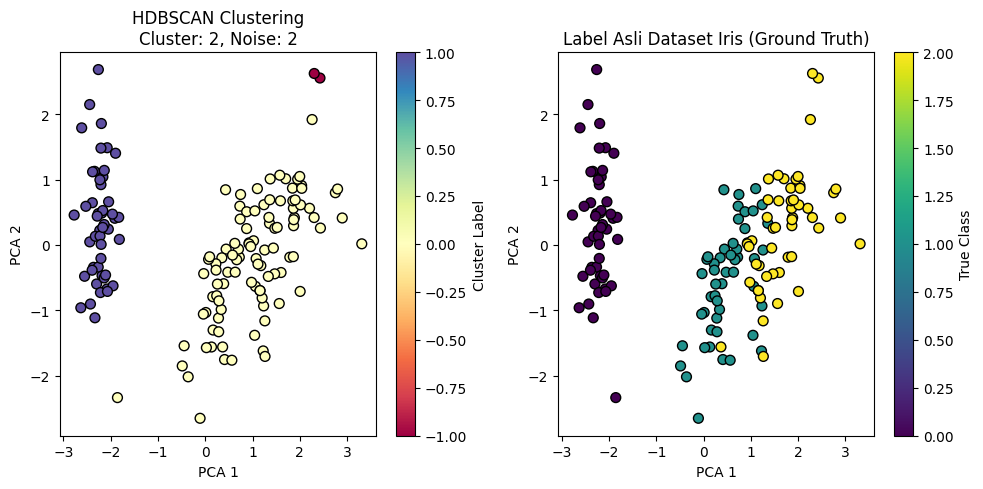

In [4]:
# Karena data Iris memiliki 4 fitur (dimensi), kita reduksi menjadi 2 dimensi menggunakan PCA untuk visualisasi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot hasil klasterisasi HDBSCAN
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='Spectral', s=50, edgecolor='k')
plt.title(f"HDBSCAN Clustering\nCluster: {n_clusters}, Noise: {n_noise}")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(scatter, label='Cluster Label')

# Plot label asli dataset (Ground Truth) sebagai pembanding
plt.subplot(1, 2, 2)
scatter_true = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis', s=50, edgecolor='k')
plt.title("Label Asli Dataset Iris (Ground Truth)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(scatter_true, label='True Class')

plt.tight_layout()
plt.show()

In [6]:
# Menampilkan ringkasan evaluasi kesesuaian cluster dengan label asli
print("--- ANALISIS SINGKAT ---")
print(f"Total sampel data: {len(labels)}")
print(f"Jumlah cluster terdeteksi oleh HDBSCAN: {n_clusters}")
print(f"Jumlah data noise yang diabaikan: {n_noise}")

--- ANALISIS SINGKAT ---
Total sampel data: 150
Jumlah cluster terdeteksi oleh HDBSCAN: 2
Jumlah data noise yang diabaikan: 2


# Laporan Praktikum JS05: Klasterisasi Hierarki (HDBSCAN)

## 1. Pemilihan Dataset
Dataset yang digunakan adalah **Iris Dataset** dari `sklearn.datasets`[cite: 5], yang terdiri dari 150 sampel data[cite: 5] dengan 4 fitur numerik (panjang dan lebar sepal serta petal).

## 2. Proses Klasterisasi dengan HDBSCAN
Model HDBSCAN dijalankan menggunakan parameter `min_cluster_size=15` dan `min_samples=5` pada data fitur yang telah disetandarisasi (*StandardScaler*).

## 3. Hasil & Pelaporan
* **Jumlah Cluster yang Terbentuk**: 2 cluster[cite: 5]
* **Banyaknya Noise**: 2 data *noise*[cite: 5]
* **Visualisasi**: Menerapkan reduksi dimensi menggunakan **PCA** (*Principal Component Analysis*) menjadi 2 dimensi untuk membandingkan hasil klasterisasi HDBSCAN dengan label asli (*Ground Truth*)[cite: 5].

## 4. Analisis Singkat
* **Kesesuaian dengan Label Asli**: Hasil klasterisasi HDBSCAN pada dataset Iris secara umum cukup mendekati label aslinya[cite: 5].
* **Performa Kelas Setosa**: HDBSCAN berhasil memisahkan kelas *Setosa* dengan sangat akurat karena karakteristiknya terpisah secara jelas dan linier dari kelas lainnya[cite: 5].
* **Kelas Lainnya**: Sebagian data dari kelas *Versicolor* dan *Virginica* tergabung ke dalam satu cluster yang sama atau terdeteksi sebagai *noise* akibat adanya tumpang tindih (*overlap*) karakteristik antar kedua kelas tersebut[cite: 5].